**Instalación de librerías necesarias**

In [4]:
!pip -q install roboflow ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 129.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.9 MB/s eta 0:00:00


**Descarga de dataset personalizado desde Roboflow**

In [15]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="T1ghJljWTm1gt4p9pFzh")
project = rf.workspace("aranza-malillany-cerda-chavez-s-workspace").project("custom-object-detection-aranza")
version = project.version(3)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to custom-object-detection-aranza-3 in yolo26:: 100%|██████████| 154/154 [00:00<00:00, 8431.20it/s]


Carga del modelo base YOLOv26 de Ultralytics

In [16]:
from ultralytics import YOLO
model = YOLO("yolo26s.pt")

**Entrenamiento del modelo personalizado**



In [20]:
data_path = "/content/custom-object-detection-aranza-3/data.yaml"
results = model.train(data=data_path,
                      epochs=15,
                      imgsz=640)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/custom-object-detection-aranza-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-8, nbs=64, nms=None, opset=None,

**Hacer predicciones**


image 1/20 /content/custom-object-detection-aranza-3/test/images/IMG_8026_jpg.rf.d4c700c4ed3f8dbac36be0b41949fb27.jpg: 640x640 (no detections), 23.5ms
image 2/20 /content/custom-object-detection-aranza-3/test/images/IMG_8027_jpg.rf.8cef88385d70441de8eab5917ab7386f.jpg: 640x640 1 pegamento, 23.6ms
image 3/20 /content/custom-object-detection-aranza-3/test/images/IMG_8033_jpg.rf.ce341c596fde0cf6aacbec5c374f2284.jpg: 640x640 1 pegamento, 23.6ms
image 4/20 /content/custom-object-detection-aranza-3/test/images/IMG_8035_jpg.rf.342a443ac2c91bd6f5a4627f3a169650.jpg: 640x640 1 pegamento, 23.5ms
image 5/20 /content/custom-object-detection-aranza-3/test/images/IMG_8040_jpg.rf.2f0b895e7cc7b622bb2d06f9e4d3d6ed.jpg: 640x640 (no detections), 23.5ms
image 6/20 /content/custom-object-detection-aranza-3/test/images/IMG_8045_jpg.rf.3e46dbe5551c3b53ad1d257e781981d3.jpg: 640x640 1 pegamento, 14.7ms
image 7/20 /content/custom-object-detection-aranza-3/test/images/IMG_8046_jpg.rf.490886606c5f83c5b26de45d6611

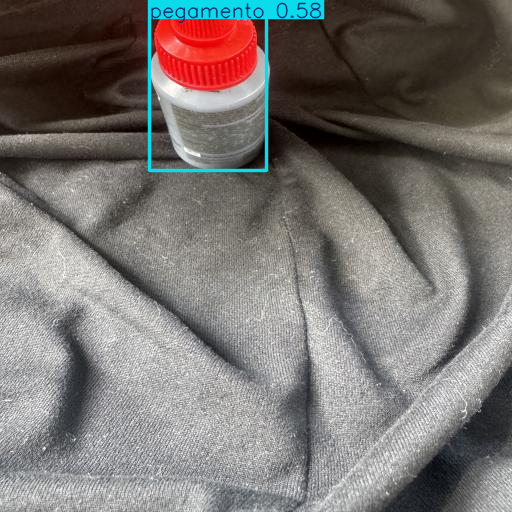

In [21]:
# Cargamos el modelo ya entrenado
custom_model = YOLO("/content/runs/detect/train-8/weights/best.pt")

# Realizamos predicciones sobre algunas imágenes
res = custom_model("/content/custom-object-detection-aranza-3/test/images")

# Visualizamos los resultados de las detecciones
res[6].show()

**Prueba tu modelo en video en vivo (Webcam)**

In [22]:
import cv2
import numpy as np
from PIL import Image
import io
import html
import time
from IPython.display import display, Javascript, Image as IPImage
from google.colab.output import eval_js
from base64 import b64decode, b64encode

# Función para convertir el recuadro de JavaScript a una imagen OpenCV
def js_to_image(js_reply):
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    img = cv2.imdecode(jpg_as_np, flags=cv2.IMREAD_COLOR)
    return img

# Función para convertir la imagen anotada de OpenCV a bytes para mostrarla en JS
def bbox_to_bytes(bbox_array):
    bbox_PIL = Image.fromarray(bbox_array)
    io_buf = io.BytesIO()
    bbox_PIL.save(io_buf, format='jpeg')
    bbox_bytes = 'data:image/jpeg;base64,{}'.format((str(b64encode(io_buf.getvalue()), 'utf-8')))
    return bbox_bytes

# JavaScript para inicializar y transmitir la cámara en vivo
def video_stream():
    js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;

    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
        stream.getTracks().forEach(track => track.stop());
        video.remove();
        div.remove();
        video = null;
        div = null;
    }

    function createDom() {
        if (div !== null) return;

        div = document.createElement('div');
        div.style.border = '2px solid black';
        div.style.padding = '10px';
        div.style.width = '640px';
        div.style.maxWidth = '100%';
        div.style.background = '#f0f0f0';

        labelElement = document.createElement('div');
        labelElement.innerText = "Cargando cámara...";
        labelElement.style.fontWeight = 'bold';
        div.appendChild(labelElement);

        video = document.createElement('video');
        video.style.display = 'block';
        video.width = 640;
        video.height = 480;
        video.autoplay = true;
        div.appendChild(video);

        imgElement = document.createElement('img');
        imgElement.style.position = 'absolute';
        imgElement.style.zIndex = '1';
        imgElement.style.top = video.offsetTop + 'px';
        imgElement.style.left = video.offsetLeft + 'px';
        imgElement.width = 640;
        imgElement.height = 480;
        // Se comenta esta línea para ver la superposición si deseas
        // div.appendChild(imgElement);

        const stopBtn = document.createElement('button');
        stopBtn.innerText = "Detener Cámara";
        stopBtn.style.marginTop = '10px';
        stopBtn.onclick = () => { shutdown = true; };
        div.appendChild(stopBtn);

        document.body.appendChild(div);
    }

    async function initCamera() {
        createDom();
        stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
        video.srcObject = stream;
        await video.play();

        captureCanvas = document.createElement('canvas');
        captureCanvas.width = 640;
        captureCanvas.height = 480;
        labelElement.innerText = "Cámara en vivo con YOLO (Presiona Detener para finalizar)";
    }

    async function streamFrame() {
        if (shutdown) {
            removeDom();
            return 'shutdown';
        }
        if (pendingResolve) return null;

        var ctx = captureCanvas.getContext('2d');
        ctx.drawImage(video, 0, 0, 640, 480);
        return captureCanvas.toDataURL('image/jpeg', 0.8);
    }

    window.initCamera = initCamera;
    window.streamFrame = streamFrame;
    ''')
    display(js)


<IPython.core.display.Javascript object>

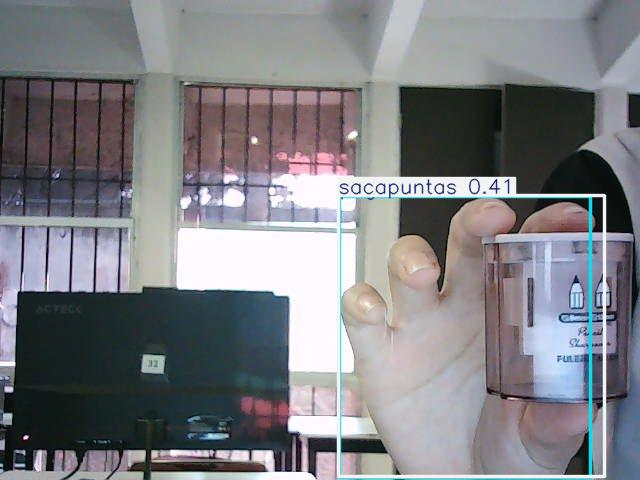

KeyboardInterrupt: 

In [25]:
from ultralytics import YOLO
from IPython.display import clear_output

# 1. Cargamos tu modelo YOLO
model = YOLO("/content/runs/detect/train-8/weights/best.pt")

# 2. Iniciamos la cámara en el navegador
video_stream()
eval_js('initCamera()')

# 3. Contenedor para mostrar los resultados en tiempo real
display_handle = display(None, display_id=True)

while True:
    # Capturamos el frame actual desde JavaScript
    js_reply = eval_js('streamFrame()')
    if js_reply == 'shutdown' or js_reply is None:
        print("Transmisión finalizada.")
        break

    # Convertimos la respuesta a formato OpenCV (BGR)
    frame = js_to_image(js_reply)

    # Realizamos la inferencia de YOLO sobre el frame
    results = model(frame, verbose=False)

    # Extraemos y dibujamos los resultados
    annotated_frame = results[0].plot()

    # El método .plot() devuelve BGR, lo pasamos a RGB para mostrarlo correctamente
    annotated_frame_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

    # Convertimos a bytes e introducimos el frame procesado al cuaderno
    img_bytes = bbox_to_bytes(annotated_frame_rgb)

    # Actualizamos la imagen en pantalla en la misma posición sin parpadeos
    display_handle.update(IPImage(data=b64decode(img_bytes.split(',')[1])))


**Recomendaciones para entrenar un detector de objetos personalizado**

Algunos consejos para llevar a cabo el entrenamiento de modelos personalizados, como el que realizamos en esta práctica:

>    Recuerda que entre más imágenes (de los objetos) utilices para entrenar el modelo, este será más robusto.
>    Al momento de crear el dataset, no olvides capturar fotos desde distintos ángulos, con diferentes iluminaciones y en fondos variados.
>   Asegúrate de colocar los objetos en entornos similares a donde serán detectados.

Experimenta para mejorar:

*   Cambia el número de epochs y observa cómo evoluciona el rendimiento.
*   Prueba con diferentes modelos base (yolo11n, yolo11s, yolo11m, etc.) según tus necesidades y capacidad computacional.


        
        
